importing libaries

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# loadiing Data

In [2]:
df=pd.read_csv("data.csv")
df.head()

,PROSPECTID,pct_tl_open_L6M,pct_tl_closed_L6M,Tot_TL_closed_L12M,pct_tl_closed_L12M,Tot_Missed_Pmnt,CC_TL,Home_TL,PL_TL,Secured_TL,...,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,HL_Flag,GL_Flag,MARITALSTATUS,EDUCATION,GENDER,last_prod_enq2,first_prod_enq2,Approved_Flag
0,1,0.000,0.0,0,0.000,0,0,0,4,1,...,0.000,0.0,1,0,1,2,1,PL,PL,2
1,2,0.000,0.0,0,0.000,0,0,0,0,0,...,0.000,0.0,0,0,0,3,0,ConsumerLoan,ConsumerLoan,2
2,3,0.125,0.0,0,0.000,1,0,0,0,2,...,0.000,0.0,1,0,1,1,1,ConsumerLoan,others,2
3,5,0.000,0.0,0,0.000,0,0,0,0,3,...,0.000,0.0,0,0,1,4,1,AL,AL,1
4,6,0.000,0.0,1,0.167,0,0,0,0,6,...,0.429,0.0,1,0,1,2,1,ConsumerLoan,PL,3


# . Approval Outcome Analysis

<Axes: title={'center': 'distribution of Approved Flag'}, xlabel='Approved_Flag'>

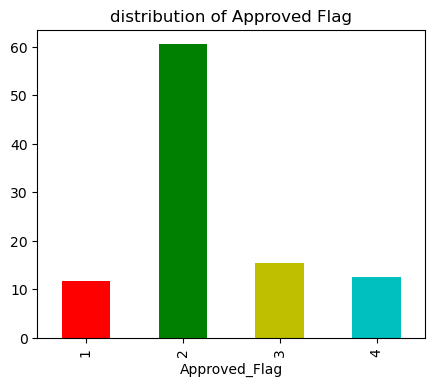

In [3]:
((df["Approved_Flag"].value_counts().sort_index()/len(df["Approved_Flag"]))*100).plot(kind="bar",color=["r","g","y","c"],title="distribution of Approved Flag",figsize=(5,4))


In [4]:
def income_segment(income):
    if income < 25000:
        return "Low"
    elif income < 50000:
        return "Medium"
    else:
        return "High"

In [5]:
df["income"]=df["NETMONTHLYINCOME"].apply(income_segment)
df["income"].value_counts()

income
Low       21428
Medium    17961
High       2675
Name: count, dtype: int64

In [6]:
(pd.crosstab(df["income"],df["Approved_Flag"],normalize="index")*100)

Approved_Flag,1,2,3,4
income,,,,
High,17.271028,55.925234,14.056075,12.747664
Low,9.366250,62.422998,16.044428,12.166324
Medium,13.579422,58.905406,14.620567,12.894605


In [7]:
#(pd.crosstab(df["Approved_Flag"],df["income"],normalize="columns")*100).plot(kind="bar",title="approved with income",figsize=(5,4))

<Axes: title={'center': 'approved with income'}, xlabel='income'>

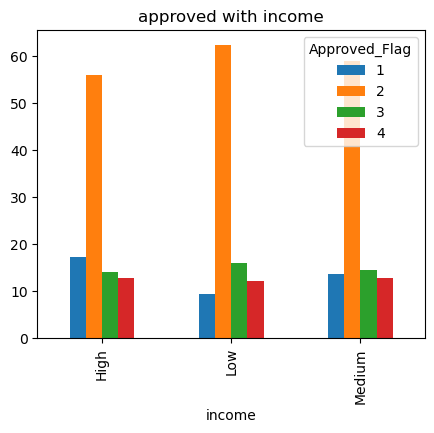

In [8]:
(pd.crosstab(df["income"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar",title="approved with income",figsize=(5,4))

# who have high salary can not prefered take loan 
# but low and medium are high iin all level 

In [9]:
# approved with gender

# thier are large no of male 

In [10]:
df["GENDER"].value_counts()

GENDER
1    37345
0     4719
Name: count, dtype: int64

<Axes: title={'center': 'approved with gender'}, xlabel='Approved_Flag'>

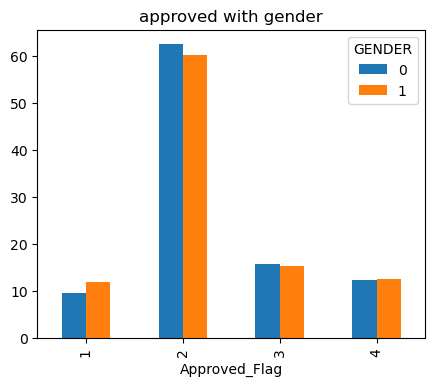

In [11]:
(pd.crosstab(df["Approved_Flag"],df["GENDER"],normalize="columns")*100).plot(kind="bar",figsize=(5,4),title="approved with gender",legend=["female","male"])

In [39]:
# marital staus with approval


In [13]:
df["MARITALSTATUS"].value_counts()

MARITALSTATUS
1    30886
0    11178
Name: count, dtype: int64

<Axes: title={'center': 'approved with maritial status'}, xlabel='Approved_Flag'>

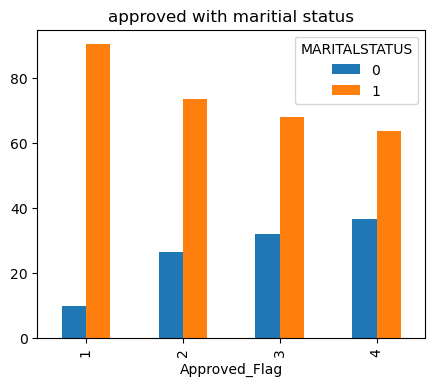

In [38]:
(pd.crosstab(df["Approved_Flag"],df["MARITALSTATUS"],normalize="index")*100).plot(kind="bar",title="approved with maritial status",figsize=(5,4))

In [44]:
pd.crosstab(df["income"],df["MARITALSTATUS"],normalize="index")*100

MARITALSTATUS,0,1
income,,
High,20.186916,79.813084
Low,30.194139,69.805861
Medium,23.205835,76.794165


In [16]:
# education distribution:

# higher member are in group 3  (ug,gradute,professional)
# and lower member are in group 4  (pg)
# and moderate in group 1,2  (ssc , 12 th ,other )

<Axes: xlabel='EDUCATION'>

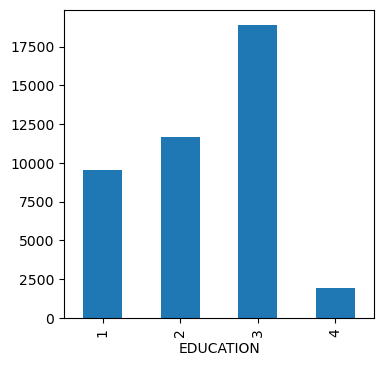

In [17]:
(df["EDUCATION"].value_counts().sort_index()).plot(kind="bar",figsize=(4,4))

In [18]:
# approved with education level

# in approved level 2  all education are equal 
# in all approved flag are equal eduacion level 

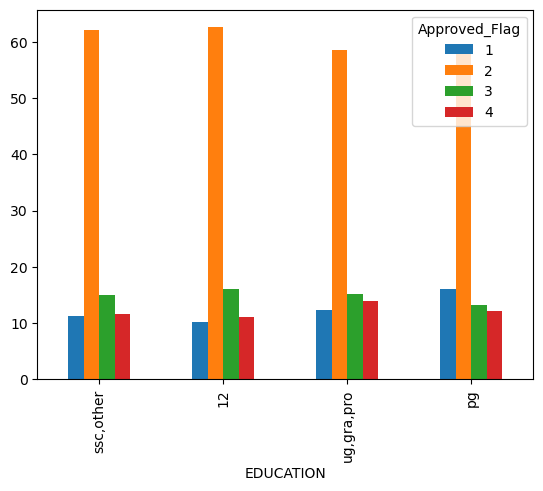

In [57]:
(pd.crosstab(df["EDUCATION"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar")
plt.xticks(ticks=[0,1,2,3],labels=["ssc,other","12","ug,gra,pro","pg"])
plt.show()

In [22]:
# apply feature engenring  in total missed payment

In [23]:
def pmt(i):
    if i == 0:
        return "No"
    elif i < 5:
        return "Low"
    elif i < 15:
        return "Medium"
    else:
        return "High"

In [24]:
# distibuton of missed payment 

# 70 % are no misses 
# 2% are highly missed

In [178]:
df["Tot_Missed_Pmnt"].value_counts()

Tot_Missed_Pmnt
0     29070
1      8164
2      2807
3      1100
4       424
5       220
6       121
7        51
8        36
9        19
11       14
10       14
12        6
13        5
15        4
16        2
28        2
34        1
19        1
23        1
17        1
27        1
Name: count, dtype: int64

In [25]:
df["mis_pmt_level"]=df["Tot_Missed_Pmnt"].apply(pmt)
df["mis_pmt_level"].value_counts(normalize=True)*100

mis_pmt_level
No        69.108977
Low       29.704736
Medium     1.155382
High       0.030905
Name: proportion, dtype: float64

<Axes: xlabel='mis_pmt_level'>

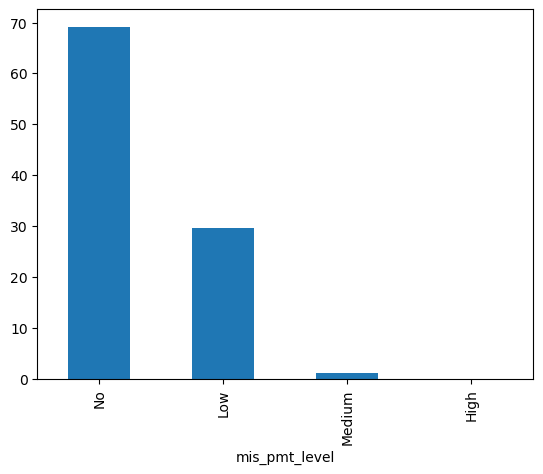

In [26]:
(df["mis_pmt_level"].value_counts(normalize=True)*100).plot(kind="bar")

In [27]:
#Do applicants with more missed payments (Tot_Missed_Pmnt) have lower approval rates?

<Axes: xlabel='mis_pmt_level'>

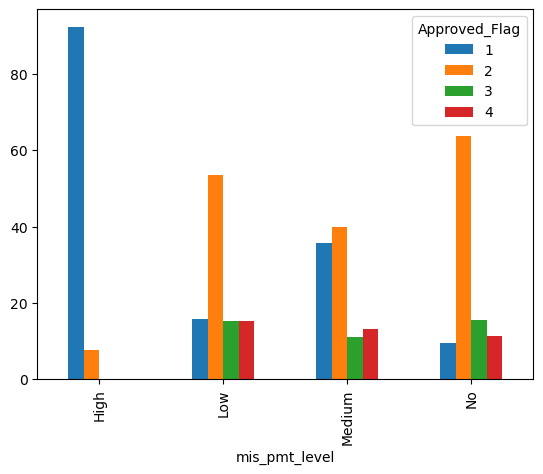

In [58]:
(pd.crosstab(df["mis_pmt_level"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar")

In [60]:
import scipy.stats as ss


In [62]:
d=pd.crosstab(df["mis_pmt_level"],df["Approved_Flag"])

In [64]:
stats,pvalues,dof,expected=ss.chi2_contingency(d)
print(stats,pvalues)

932.7111240236219 5.5269206919610945e-195


In [65]:
# deliquency with approved Flag

In [68]:
def deliq_level(x):
    if x == 0:
        return "No"
    elif x <= 2:
        return "Low"
    elif x <= 5:
        return "Medium"
    else:
        return "High"

df["deliq_level_6-12"] = df["num_deliq_6_12mts"].apply(deliq_level)

<Axes: xlabel='deliq_level_6-12'>

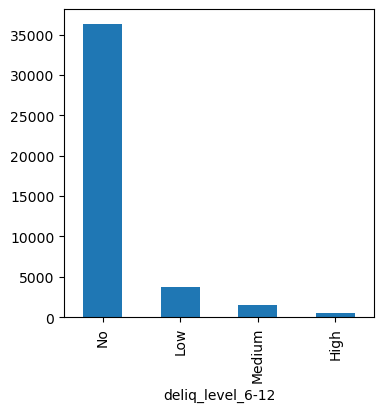

In [71]:
df["deliq_level_6-12"].value_counts().plot(kind="bar",figsize=(4,4))

<Axes: xlabel='Approved_Flag'>

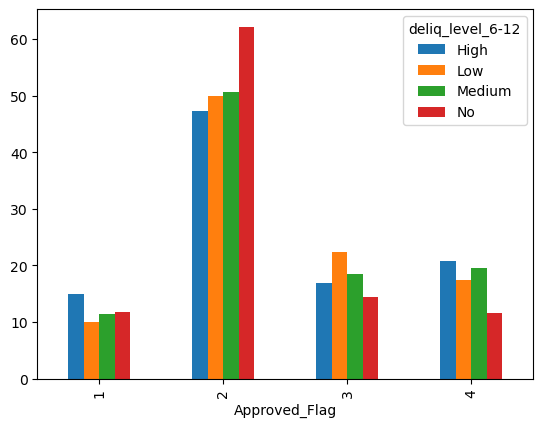

In [81]:
(pd.crosstab(df["Approved_Flag"],df["deliq_level_6-12"],normalize="columns")*100).plot(kind="bar")

In [77]:
s,p,_,_=ss.chi2_contingency(d)
p

np.float64(1.4086169186971267e-96)

In [87]:
# dpd with approevd Flag

<Axes: xlabel='dpd'>

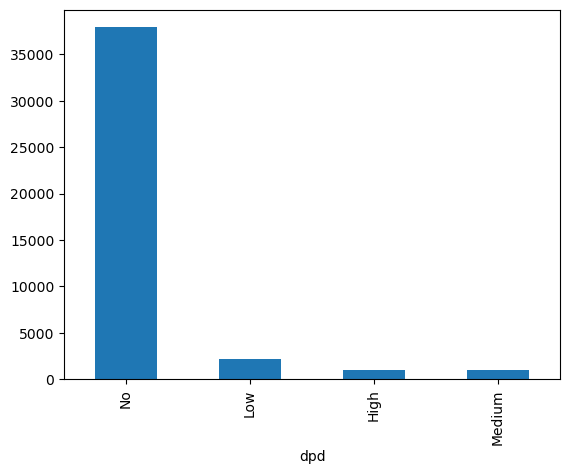

In [86]:
df["dpd"]=df["num_times_60p_dpd"].apply(deliq_level)
df["dpd"].value_counts().plot(kind="bar")

<Axes: xlabel='dpd'>

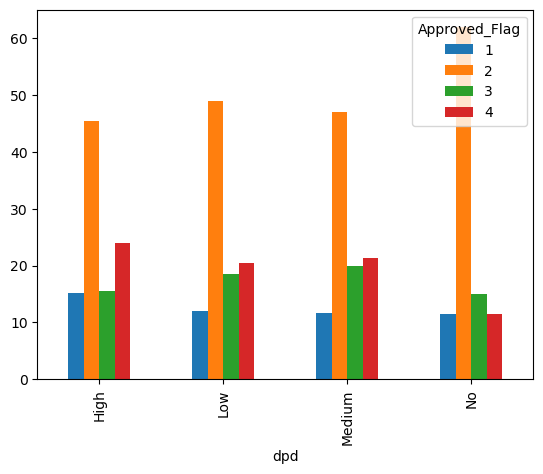

In [89]:
(pd.crosstab(df["dpd"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar")

In [100]:
# oldest_tl with approved Flag

In [93]:
df["Age_Oldest_TL"].describe()

count    42064.000000
mean        46.498074
std         42.109230
min          0.000000
25%         14.000000
50%         34.000000
75%         65.000000
max        385.000000
Name: Age_Oldest_TL, dtype: float64

In [94]:
def credit_history_level(x):
    if x <= 60:
        return "Short"
    elif x <= 120:
        return "Medium"
    elif x <= 240:
        return "Long"
    else:
        return "Very Long"

df["credit_history_level"] = df["Age_Oldest_TL"].apply(credit_history_level)

<Axes: xlabel='credit_history_level'>

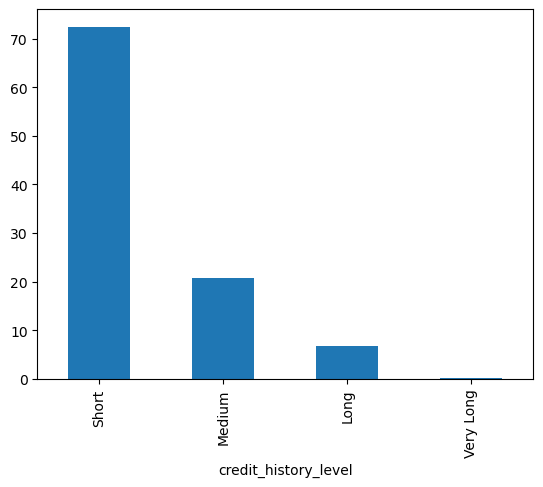

In [115]:
(df["credit_history_level"].value_counts(normalize=True)*100).plot(kind="bar")

In [99]:
#Does a longer credit history (Age_Oldest_TL) correspond to better approval outcomes?


<Axes: xlabel='credit_history_level'>

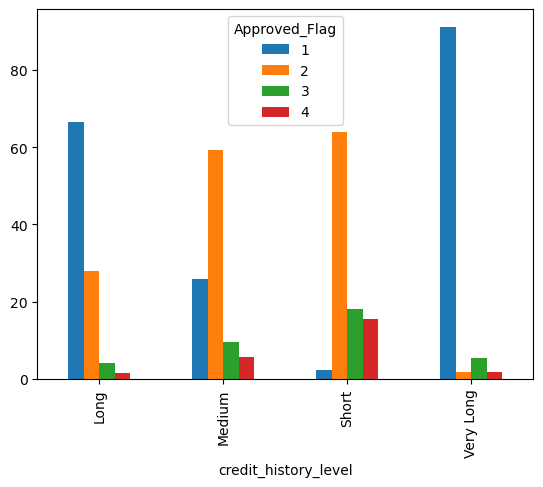

In [98]:
(pd.crosstab(df["credit_history_level"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar")

In [120]:
# new tradeline with approved flag

#Does the age of the newest trade line (Age_Newest_TL) affect approval?

In [102]:
df["Age_Newest_TL"].describe()

count    42064.000000
mean        13.970046
std         18.835191
min          0.000000
25%          4.000000
50%          7.000000
75%         16.000000
max        359.000000
Name: Age_Newest_TL, dtype: float64

In [110]:
def newest_tl_level(x):
    if x <= 12:
        return "Very Recent"
    elif x <= 36:
        return "Recent"
    elif x <= 120:
        return "Moderate"
    else:
        return "Old"

df["newest_tl_level"] = df["Age_Newest_TL"].apply(newest_tl_level)

<Axes: xlabel='newest_tl_level'>

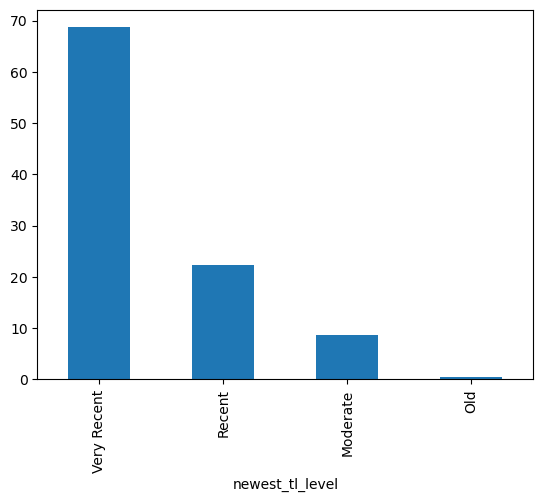

In [114]:
(df["newest_tl_level"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='newest_tl_level'>

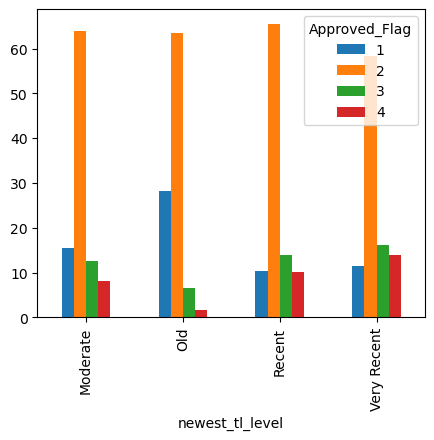

In [119]:
(pd.crosstab(df["newest_tl_level"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar",figsize=(5,4))

In [133]:
# time since recent payment with approved Flag

In [122]:
df["time_since_recent_payment"].describe()

count    42064.000000
mean       218.601607
std        422.282417
min          2.000000
25%         51.000000
50%         71.000000
75%        146.000000
max       6065.000000
Name: time_since_recent_payment, dtype: float64

In [124]:
df["time_since_recent_payment"].quantile(0.90)

np.float64(574.0)

In [125]:
def recent_payment_level(x):
    if x <= 51:
        return "Very Recent"
    elif x <= 71:
        return "Recent"
    elif x <= 146:
        return "Moderate"
    else:
        return "Long"

df["recent_payment_level"] = df["time_since_recent_payment"].apply(recent_payment_level)

<Axes: xlabel='recent_payment_level'>

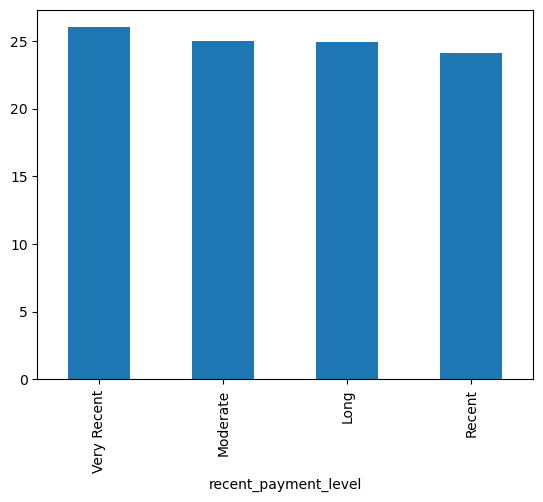

In [127]:
(df["recent_payment_level"].value_counts(normalize=True)*100).plot(kind="bar")

In [128]:
df['recent_payment_level'].value_counts()

recent_payment_level
Very Recent    10939
Moderate       10512
Long           10486
Recent         10127
Name: count, dtype: int64

In [134]:
# credit card 

In [135]:
df["CC_TL"].value_counts()

CC_TL
0     37733
1      3306
2       635
3       211
4        99
5        33
6        20
7        11
8         7
9         3
13        2
10        1
27        1
11        1
14        1
Name: count, dtype: int64

<Axes: xlabel='cc'>

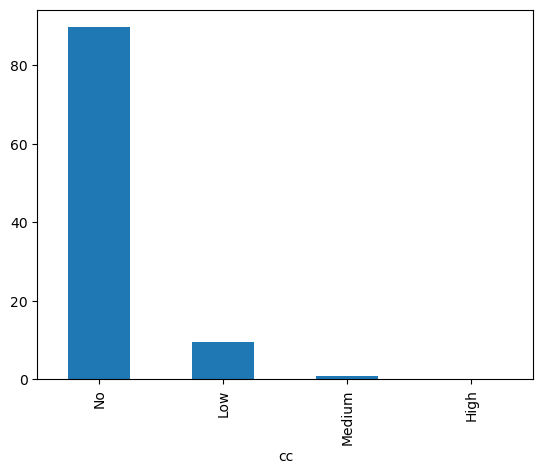

In [137]:
df["cc"]=df["CC_TL"].apply(deliq_level)
(df["cc"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='pl'>

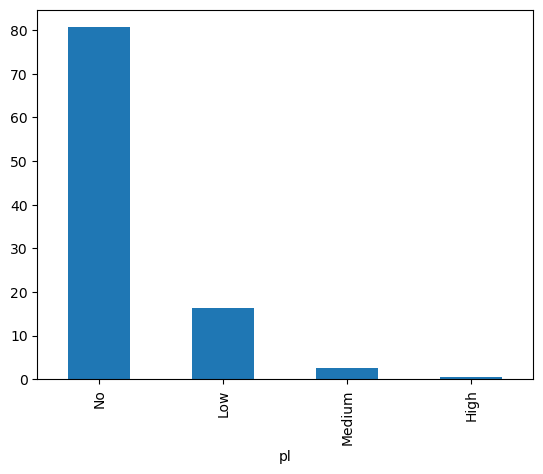

In [139]:
df["pl"]=df["PL_TL"].apply(deliq_level)

(df["pl"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='cc'>

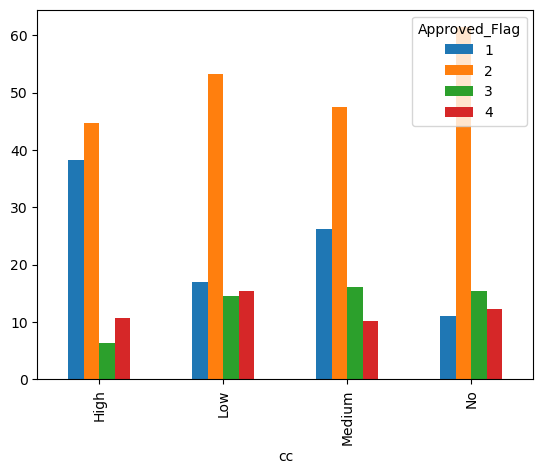

In [150]:
(pd.crosstab(df["cc"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar")

<Axes: xlabel='pl'>

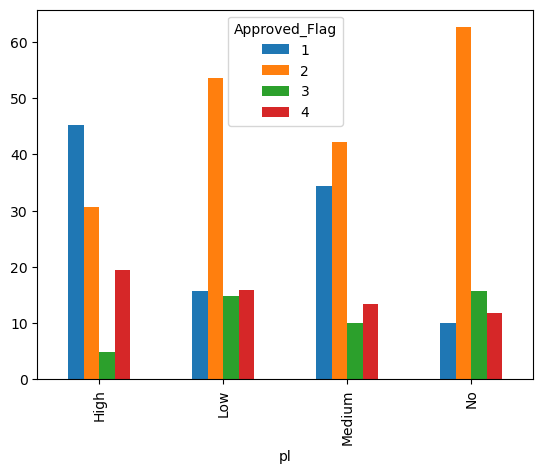

In [151]:
(pd.crosstab(df["pl"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar")

In [158]:
df[["Secured_TL", "Unsecured_TL"]].describe()

,Secured_TL,Unsecured_TL
count,42064.000000,42064.000000
mean,2.921334,2.341646
std,6.379764,3.405397
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,1.000000
75%,3.000000,3.000000
max,235.000000,55.000000


In [170]:
def tl_type(row):
    if row["Secured_TL"] > row["Unsecured_TL"]:
        return "Secured"
    elif row["Unsecured_TL"] > row["Secured_TL"]:
        return "Unsecured"
    else:
        return "Equal"

df["tl_type"] = df.apply(tl_type, axis=1)

<Axes: xlabel='tl_type'>

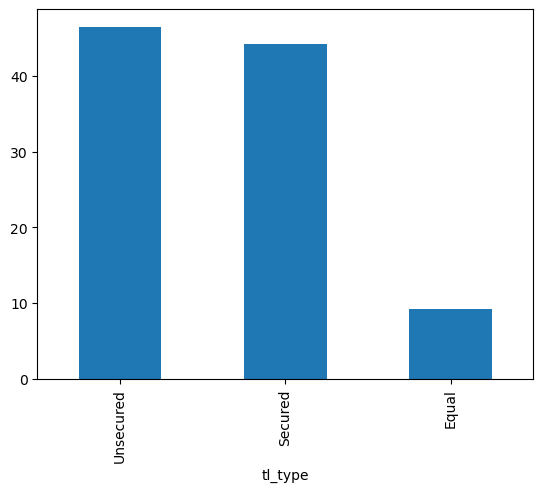

In [171]:
(df["tl_type"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='tl_type'>

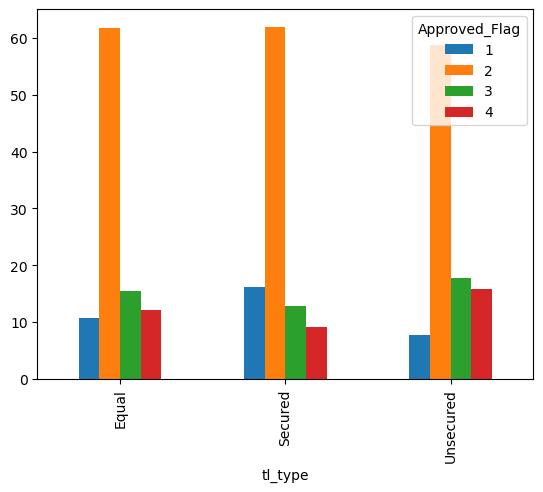

In [172]:
(pd.crosstab(df["tl_type"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar")

In [173]:
df["Tot_TL_closed_L12M"].describe()

count    42064.000000
mean         0.825504
std          1.537208
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         33.000000
Name: Tot_TL_closed_L12M, dtype: float64

In [174]:
def closed_tl_level(x):
    if x == 0:
        return "No Closure"
    elif x <= 1:
        return "Low"
    elif x <= 3:
        return "Medium"
    else:
        return "High"

df["closed_tl_level"] = df["Tot_TL_closed_L12M"].apply(closed_tl_level)

<Axes: xlabel='closed_tl_level'>

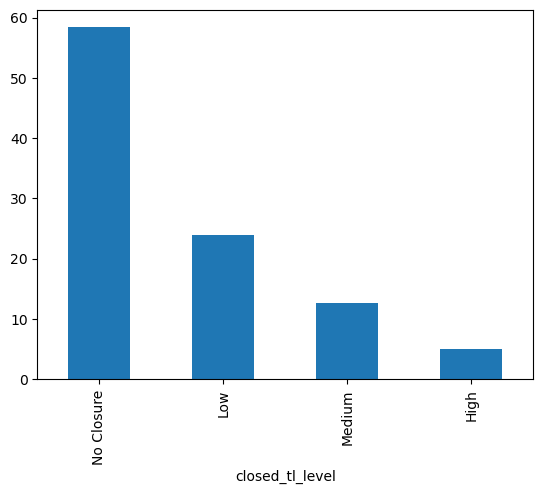

In [175]:
(df["closed_tl_level"].value_counts(normalize=True)*100).plot(kind="bar")

In [176]:
pd.crosstab(df["closed_tl_level"],df["Approved_Flag"],normalize="index")*100

Approved_Flag,1,2,3,4
closed_tl_level,,,,
High,21.960596,49.014897,13.262854,15.761653
Low,11.364538,60.759619,15.103134,12.772709
Medium,17.190423,55.798728,14.496820,12.514029
No Closure,9.717753,62.403780,15.745530,12.132937


<Axes: xlabel='cc_enq'>

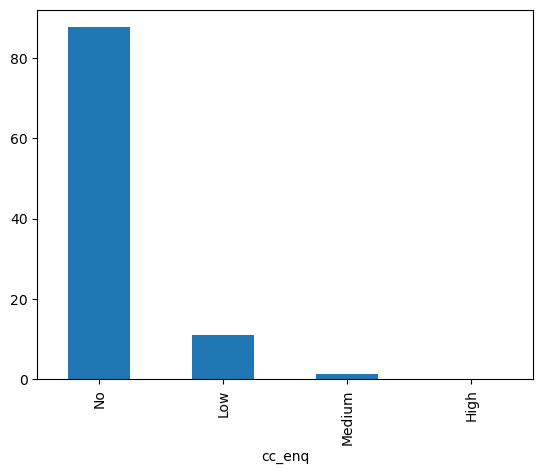

In [182]:
df["cc_enq"]=df["CC_enq_L12m"].apply(pmt)
(df["cc_enq"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='pp_enq'>

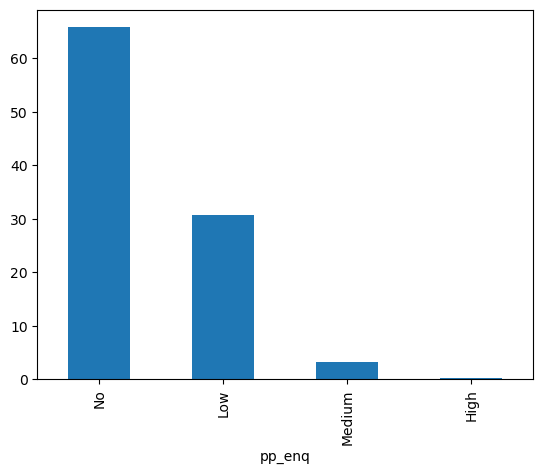

In [183]:
df["pp_enq"]=df['PL_enq_L12m'].apply(pmt)
(df["pp_enq"].value_counts(normalize=True)*100).plot(kind="bar")

In [185]:
pd.crosstab(df["cc_enq"],df["Approved_Flag"],normalize="index")*100

Approved_Flag,1,2,3,4
cc_enq,,,,
High,0.000000,0.000000,0.000000,100.000000
Low,8.498279,48.192771,17.469880,25.839071
Medium,4.112150,26.355140,18.878505,50.654206
No,12.179974,62.570514,14.989694,10.259818


In [186]:
pd.crosstab(df["pp_enq"],df["Approved_Flag"],normalize="index")*100

Approved_Flag,1,2,3,4
pp_enq,,,,
High,2.105263,9.473684,9.473684,78.947368
Low,7.159407,49.181341,21.215632,22.443621
Medium,3.089676,26.902788,16.955539,53.051997
No,14.219687,67.588647,12.490070,5.701596


<Axes: xlabel='enql3'>

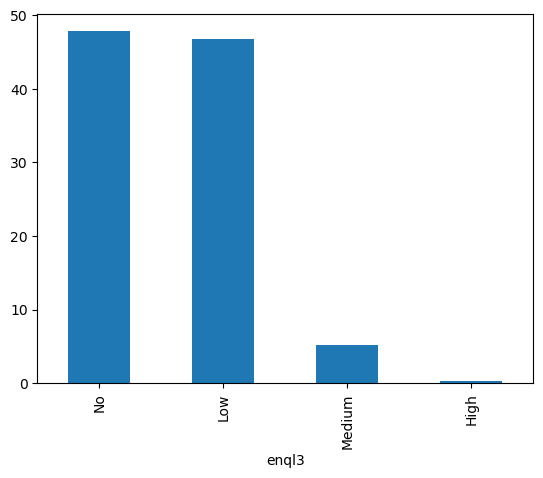

In [193]:
df["enql3"]=df["enq_L3m"].apply(pmt)
(df["enql3"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='enql3'>

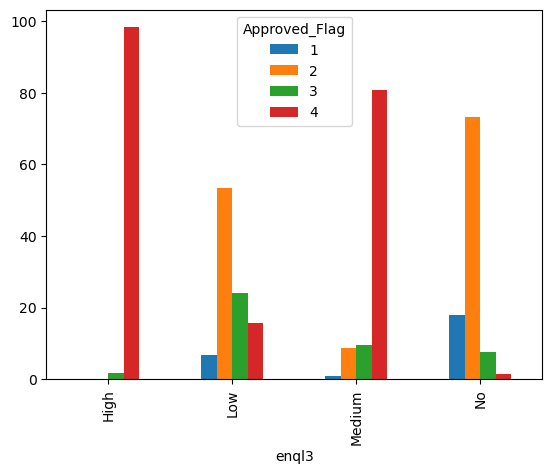

In [195]:
(pd.crosstab(df["enql3"],df["Approved_Flag"],normalize="index")*100).plot(kind="bar")

In [197]:
df['time_since_recent_enq'].describe()

count    42064.000000
mean       264.854507
std        466.585002
min          0.000000
25%          9.000000
50%         79.000000
75%        302.000000
max       4768.000000
Name: time_since_recent_enq, dtype: float64

In [198]:
df["last_prod_enq2"].value_counts()

last_prod_enq2
ConsumerLoan    16480
others          13653
PL               7553
CC               2195
AL               1353
HL                830
Name: count, dtype: int64

In [200]:
df["first_prod_enq2"].value_counts()

first_prod_enq2
others          20640
ConsumerLoan    11075
PL               4431
AL               2641
CC               1988
HL               1289
Name: count, dtype: int64

In [202]:
pd.crosstab(df["first_prod_enq2"],df["Approved_Flag"],normalize="index")*100

Approved_Flag,1,2,3,4
first_prod_enq2,,,,
AL,19.462325,60.583112,11.094282,8.860280
CC,12.877264,53.672032,15.191147,18.259557
ConsumerLoan,5.887133,59.674944,17.878104,16.559819
HL,27.152832,57.020946,9.697440,6.128782
PL,17.129316,53.125705,15.707515,14.037463
others,11.516473,63.406008,14.748062,10.329457


In [203]:
pd.crosstab(df["last_prod_enq2"],df["Approved_Flag"],normalize="index")*100

Approved_Flag,1,2,3,4
last_prod_enq2,,,,
AL,24.464154,62.232077,8.943089,4.360680
CC,14.031891,59.908884,13.075171,12.984055
ConsumerLoan,7.360437,55.989078,18.762136,17.888350
HL,28.554217,61.566265,7.590361,2.289157
PL,11.717198,54.892096,18.244406,15.146299
others,14.165385,68.929906,10.979272,5.925438


In [284]:
# flag_categpry  with approved_flag

In [227]:
c=["GL_Flag","PL_Flag","HL_Flag","CC_Flag"]

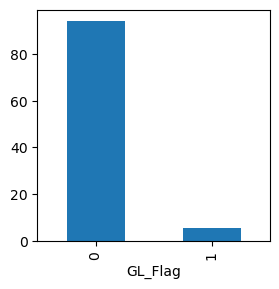

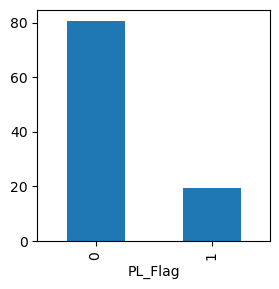

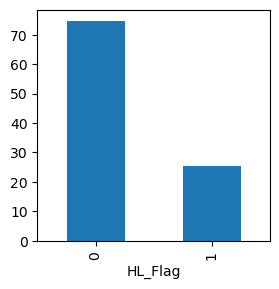

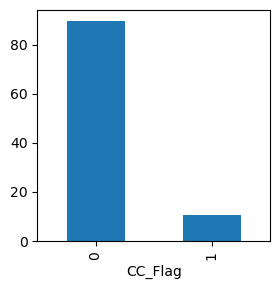

In [229]:
for i in range(len(c)):
    (df[c[i]].value_counts(normalize=True)*100).plot(kind="bar",figsize=(3,3))
    plt.show()

In [251]:
for i in range(len(c)):
    print(pd.crosstab(df[c[i]],df["Approved_Flag"],normalize="index")*100)
   

Approved_Flag          1          2          3          4
GL_Flag                                                  
0              10.213184  61.238786  15.656184  12.891846
1              35.924370  48.319328   9.537815   6.218487
Approved_Flag          1          2          3          4
PL_Flag                                                  
0               9.943140  62.634417  15.643874  11.778570
1              18.876986  51.619259  13.914543  15.589213
Approved_Flag          1          2          3          4
HL_Flag                                                  
0               8.695237  62.325936  16.195079  12.783748
1              20.480679  55.117813  12.686145  11.715363
Approved_Flag          1          2          3          4
CC_Flag                                                  
0              10.947977  61.405136  15.402963  12.243924
1              17.940429  52.689910  14.500115  14.869545


In [259]:
d=(df.groupby("GL_Flag")["Approved_Flag"].value_counts(normalize=True)*100).reset_index().sort_values(["GL_Flag","Approved_Flag"])
d[d["GL_Flag"]==1]["proportion"]

5    35.924370
4    48.319328
6     9.537815
7     6.218487
Name: proportion, dtype: float64

In [267]:
k=[]
for i in range(len(c)):
    d=(df.groupby(c[i])["Approved_Flag"].value_counts(normalize=True)*100).reset_index().sort_values([c[i],"Approved_Flag"])
    k.append(list(d[d[c[i]]==1]["proportion"].values))

In [ ]:
k

In [274]:
l=[]

for i in range(len(k)):
    v=[]
    for j in range(len(k)):
        v.append(int(k[j][i]))
    l.append(v)
l

[[35, 18, 20, 17], [48, 51, 55, 52], [9, 13, 12, 14], [6, 15, 11, 14]]

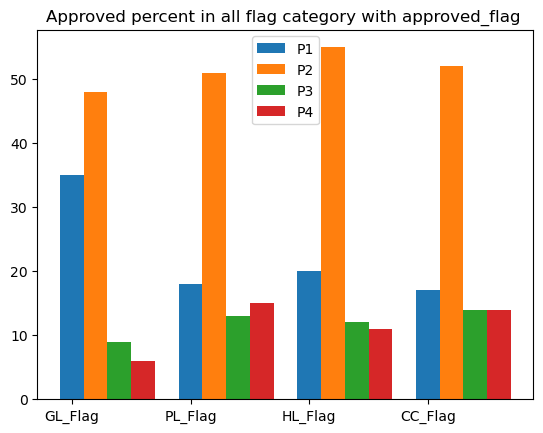

In [285]:
c=["GL_Flag","PL_Flag","HL_Flag","CC_Flag"]
x=np.array([1,2,3,4])
w=0.2
plt.bar(x,l[0],width=w,label="P1")
plt.bar(x+w,l[1],width=w,label="P2")
plt.bar(x+(2*w),l[2],width=w,label="P3")
plt.bar(x+(3*w),l[3],width=w,label="P4")
plt.xticks(ticks=[1,2,3,4],labels=c)
plt.legend()
plt.title("Approved percent in all flag category with approved_flag ")
plt.show()

In [286]:
#Which product-related flag is most strongly associated with approval?

In [292]:
c=["GL_Flag","PL_Flag","HL_Flag","CC_Flag"]
st=0
cs=""
for i in c:
    o=pd.crosstab(df[i],df["Approved_Flag"])
    s,p,_,_=ss.chi2_contingency(o)
    if p <0.05:
        print(i, "---",p)
        if st < p:
            st=p
            cs=i
print(cs , st)

GL_Flag --- 0.0
PL_Flag --- 1.4128943414326572e-144
HL_Flag --- 1.304465971688177e-234
CC_Flag --- 1.1228628923093789e-50
CC_Flag 1.1228628923093789e-50


In [4]:
#statically analysis

In [5]:
# correlation 


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42064 entries, 0 to 42063
Data columns (total 44 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PROSPECTID                 42064 non-null  int64  
 1   pct_tl_open_L6M            42064 non-null  float64
 2   pct_tl_closed_L6M          42064 non-null  float64
 3   Tot_TL_closed_L12M         42064 non-null  int64  
 4   pct_tl_closed_L12M         42064 non-null  float64
 5   Tot_Missed_Pmnt            42064 non-null  int64  
 6   CC_TL                      42064 non-null  int64  
 7   Home_TL                    42064 non-null  int64  
 8   PL_TL                      42064 non-null  int64  
 9   Secured_TL                 42064 non-null  int64  
 10  Unsecured_TL               42064 non-null  int64  
 11  Other_TL                   42064 non-null  int64  
 12  Age_Oldest_TL              42064 non-null  int64  
 13  Age_Newest_TL              42064 non-null  int

In [9]:
k=[]
for i in df.columns:
    if df[i].dtype==int and i not in ['PROSPECTID',"GENDER","MARITALSTATUS","EDUCATION","Approved_Flag"]:
        k.append(i)

<Axes: >

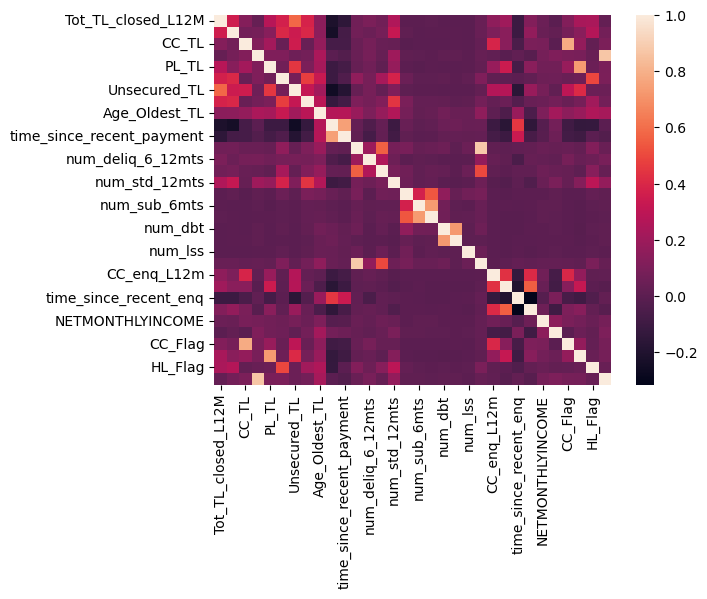

In [33]:
sns.heatmap(df[k].corr())

In [38]:
import scipy.stats as ss
nck=[]
for i in k:
    
    g1=df[df["Approved_Flag"] == 1][i]
    g2=df[df["Approved_Flag"] == 2][i]
    g3=df[df["Approved_Flag"] == 3][i]
    g4=df[df["Approved_Flag"] == 4][i]

    f_statistic , p_value=ss.f_oneway(g1,g2,g3,g4)
    print(i , "p_values",p_value)

    if p_value <=.05:
        nck.append(i)
    

Tot_TL_closed_L12M p_values 1.762685578230421e-99
Tot_Missed_Pmnt p_values 9.572404615942641e-210
CC_TL p_values 5.710261952999025e-57
Home_TL p_values 0.0
PL_TL p_values 7.991892389241125e-235
Secured_TL p_values 0.0
Unsecured_TL p_values 2.102384431982427e-118
Other_TL p_values 0.0
Age_Oldest_TL p_values 0.0
Age_Newest_TL p_values 1.0465965445912546e-88
time_since_recent_payment p_values 8.943912807416738e-81
max_recent_level_of_deliq p_values 6.699932727692095e-81
num_deliq_6_12mts p_values 2.0772229883600566e-59
num_times_60p_dpd p_values 3.3833576401764997e-59
num_std_12mts p_values 0.0
num_sub p_values 1.698554545026436e-22
num_sub_6mts p_values 0.016579119048249723
num_sub_12mts p_values 0.001299484021242129
num_dbt p_values 3.135918708089289e-11
num_dbt_12mts p_values 0.005446087209172642
num_lss p_values 0.009340555562870471
recent_level_of_deliq p_values 1.150955072948535e-97
CC_enq_L12m p_values 0.0
PL_enq_L12m p_values 0.0
time_since_recent_enq p_values 0.0
enq_L3m p_values

In [42]:
nck

['Tot_TL_closed_L12M',
 'Tot_Missed_Pmnt',
 'CC_TL',
 'Home_TL',
 'PL_TL',
 'Secured_TL',
 'Unsecured_TL',
 'Other_TL',
 'Age_Oldest_TL',
 'Age_Newest_TL',
 'time_since_recent_payment',
 'max_recent_level_of_deliq',
 'num_deliq_6_12mts',
 'num_times_60p_dpd',
 'num_std_12mts',
 'num_sub',
 'num_sub_6mts',
 'num_sub_12mts',
 'num_dbt',
 'num_dbt_12mts',
 'num_lss',
 'recent_level_of_deliq',
 'CC_enq_L12m',
 'PL_enq_L12m',
 'time_since_recent_enq',
 'enq_L3m',
 'NETMONTHLYINCOME',
 'Time_With_Curr_Empr',
 'CC_Flag',
 'PL_Flag',
 'HL_Flag',
 'GL_Flag']

In [41]:
len(k)

32

In [44]:
df["Tot_Missed_Pmnt"].value_counts()

Tot_Missed_Pmnt
0     29070
1      8164
2      2807
3      1100
4       424
5       220
6       121
7        51
8        36
9        19
11       14
10       14
12        6
13        5
15        4
16        2
28        2
34        1
19        1
23        1
17        1
27        1
Name: count, dtype: int64

In [45]:
k

['Tot_TL_closed_L12M',
 'Tot_Missed_Pmnt',
 'CC_TL',
 'Home_TL',
 'PL_TL',
 'Secured_TL',
 'Unsecured_TL',
 'Other_TL',
 'Age_Oldest_TL',
 'Age_Newest_TL',
 'time_since_recent_payment',
 'max_recent_level_of_deliq',
 'num_deliq_6_12mts',
 'num_times_60p_dpd',
 'num_std_12mts',
 'num_sub',
 'num_sub_6mts',
 'num_sub_12mts',
 'num_dbt',
 'num_dbt_12mts',
 'num_lss',
 'recent_level_of_deliq',
 'CC_enq_L12m',
 'PL_enq_L12m',
 'time_since_recent_enq',
 'enq_L3m',
 'NETMONTHLYINCOME',
 'Time_With_Curr_Empr',
 'CC_Flag',
 'PL_Flag',
 'HL_Flag',
 'GL_Flag']

In [46]:
out=["Tot_Missed_Pmnt","Secured_TL","Unsecured_TL","Age_Oldest_TL","Age_Newest_TL","time_since_recent_payment","num_deliq_6_12mts","num_times_60p_dpd","NETMONTHLYINCOME","Time_With_Curr_Empr"]

out

['Tot_Missed_Pmnt',
 'Secured_TL',
 'Unsecured_TL',
 'Age_Oldest_TL',
 'Age_Newest_TL',
 'time_since_recent_payment',
 'num_deliq_6_12mts',
 'num_times_60p_dpd',
 'NETMONTHLYINCOME',
 'Time_With_Curr_Empr']

In [71]:
for i in out:
    v=df[i].describe()[["25%","75%"]].values
    iqr=v[1]-v[0]
    l=v[0] - 1.5*iqr
    u=v[1] + 1.5*iqr
    print(i, "       outlier count:-  " ,len(df[(df[i]<l) | (df[i] > u)]))

Tot_Missed_Pmnt        outlier count:-   2023
Secured_TL        outlier count:-   3855
Unsecured_TL        outlier count:-   2678
Age_Oldest_TL        outlier count:-   1896
Age_Newest_TL        outlier count:-   4175
time_since_recent_payment        outlier count:-   7357
num_deliq_6_12mts        outlier count:-   5714
num_times_60p_dpd        outlier count:-   4153
NETMONTHLYINCOME        outlier count:-   1816
Time_With_Curr_Empr        outlier count:-   3366
